# Kopi NangKau Sales Analysis 2021-2023

Pembersihan, analisis, dan visualisasi data penjualan harian Kopi NangKau menggunakan Python (pandas, seaborn).

## [DATASET.CSV](https://drive.google.com/file/d/1D1hdilPgi6nB8W3HAHnB1Jx87OJBScm8/view?usp=sharing)

In [ ]:
!gdown 1D1hdilPgi6nB8W3HAHnB1Jx87OJBScm8 -O penjualan_kopi_2021_2023.csv

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# Tabel harga dasar tahun 2021 & aturan kenaikan 2% per tahun (simple, bukan compound)
# Contoh dari brief: Espresso 2021=22000, 2022=22000x1.02=22440, 2023=22000x1.04=22880
HARGA_DASAR = {
    'Espresso': 22000,
    'Latte': 28000,
    'Cappuccino': 25000,
    'Americano': 21000,
    'Croissant': 18000,
    'Donat': 15000
}

def harga_standar(produk, tahun):
    """Hitung harga resmi produk pada tahun tertentu sesuai aturan kenaikan 2%/tahun (simple interest, dibulatkan ke bawah)."""
    if produk not in HARGA_DASAR:
        return np.nan
    multiplier = 1 + 0.02 * (tahun - 2021)
    return int(HARGA_DASAR[produk] * multiplier)

# Lookup terbalik (tahun, harga) -> produk, dipakai untuk mengisi Produk yang kosong
HARGA_LOOKUP = {}
for produk in HARGA_DASAR:
    for tahun in [2021, 2022, 2023]:
        HARGA_LOOKUP[(tahun, harga_standar(produk, tahun))] = produk

## **Skenario:**

Selamat! Kamu baru saja direkrut sebagai `Data Analyst` di `Kopi NangKau`. Kamu diberikan data penjualan harian dari tahun 2021 hingga 2023. Data ini berisi penjualan berbagai produk minuman dan makanan di toko, tapi terdapat data dobel (duplikat) dan beberapa nilai kosong (missing value).

Tugas kamu adalah membersihkan, mengolah, dan menganalisis data penjualan supaya bisnis bisa terus berkembang.

---

### 💡 Informasi Dasar Harga Produk

| Produk      | Harga Dasar Tahun 2021 (Rp) |
|-------------|----------------------------|
| Espresso    | 22.000                     |
| Latte       | 28.000                     |
| Cappuccino  | 25.000                     |
| Americano   | 21.000                     |
| Croissant   | 18.000                     |
| Donat       | 15.000                     |

- **Harga setiap produk naik 2% setiap tahun**  
  Contoh: Jika harga awal Espresso 22.000 di 2021, maka di 2023:  
  Tahun 2022 → 22.000 × 1.02 = 22.440  
  Tahun 2023 → 22.000 × 1.04 = 22.880 (pembulatan ke bawah karena integer di kode)

---
## TUGAS 1: Eksplorasi Data

1. Baca dataset ke pandas DataFrame.
2. Tampilkan 10 baris pertama.
3. Hitung jumlah baris, kolom, baris duplikat, serta missing value per kolom.
4. Pastikan Kolom Unit_Terjual dan Harga_Per_Unit

In [ ]:
# 1. Baca dataset ke pandas DataFrame (separator titik koma sesuai format file asli)
df = pd.read_csv('/content/penjualan_kopi_2021_2023.csv', sep=';')

# 2. Tampilkan 10 baris pertama
print("10 baris pertama:")
print(df.head(10))

# 3. Hitung jumlah baris, kolom, baris duplikat, serta missing value per kolom
print(f"\nJumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")
print("\nMissing value per kolom:")
print(df.isnull().sum())

# 4. Pastikan kolom Unit_Terjual dan Harga_Per_Unit numerik
df['Unit_Terjual'] = pd.to_numeric(df['Unit_Terjual'], errors='coerce')
df['Harga_Per_Unit'] = pd.to_numeric(df['Harga_Per_Unit'], errors='coerce')

print("\nTipe data setelah konversi:")
print(df[['Unit_Terjual', 'Harga_Per_Unit']].dtypes)

10 baris pertama:
   Tahun    Bulan  Tanggal      Produk  Unit_Terjual  Harga_Per_Unit
0   2021  Januari        1   Americano          52.0         21000.0
1   2021  Januari        1  Cappuccino          45.0             NaN
2   2021  Januari        1   Croissant          20.0             NaN
3   2021  Januari        1       Donat          20.0         15000.0
4   2021  Januari        1    Espresso          43.0         22000.0
5   2021  Januari        1       Latte          38.0         28000.0
6   2021  Januari        2   Americano          44.0         21000.0
7   2021  Januari        2  Cappuccino          36.0             NaN
8   2021  Januari        2   Croissant          18.0         18000.0
9   2021  Januari        2   Croissant          18.0         18000.0

Jumlah baris: 6600, Jumlah kolom: 6
Jumlah baris duplikat: 19

Missing value per kolom:
Tahun               0
Bulan               0
Tanggal             0
Produk            500
Unit_Terjual      500
Harga_Per_Unit    500
dt

**Temuan eksplorasi data**

- Dataset berisi 6.600 baris dan 6 kolom.
- Terdapat 19 baris duplikat persis.
- Kolom `Produk`, `Unit_Terjual`, dan `Harga_Per_Unit` masing-masing memiliki 500 nilai kosong.


---

## TUGAS 2: Data Cleaning & Imputasi

1. Untuk baris di mana **Produk kosong tapi Harga_Per_Unit ada**:  
   - Lengkapi nilai Produk dengan cara mencocokkan harga dan tahun pada daftar harga.
2. Untuk baris di mana **Harga_Per_Unit kosong tapi Produk ada**:  
   - Lengkapi Harga_Per_Unit berdasar produk dan tahun (lihat tabel harga & rumus kenaikan).
3. Untuk baris dengan **Produk & Harga_Per_Unit sama-sama kosong**, hapus baris tersebut.
4. Untuk **Unit_Terjual** yang kosong, langsung hapus baris.
5. Pastikan tidak ada nilai negatif di Unit_Terjual.
6. Hapus baris duplikat.

In [ ]:

# 1. Baris Produk kosong TAPI Harga_Per_Unit ada -> cocokkan harga & tahun ke daftar harga
mask_produk_kosong = df['Produk'].isna() & df['Harga_Per_Unit'].notna()
def cari_produk_dari_harga(row):
    return HARGA_LOOKUP.get((row['Tahun'], row['Harga_Per_Unit']), np.nan)

df.loc[mask_produk_kosong, 'Produk'] = df.loc[mask_produk_kosong].apply(cari_produk_dari_harga, axis=1)
print(f"Baris Produk kosong dengan harga tersedia (dicoba dilengkapi): {mask_produk_kosong.sum()}")

# 2. Baris Harga_Per_Unit kosong TAPI Produk ada -> lengkapi pakai rumus harga & tahun
mask_harga_kosong = df['Harga_Per_Unit'].isna() & df['Produk'].notna()
df.loc[mask_harga_kosong, 'Harga_Per_Unit'] = df.loc[mask_harga_kosong].apply(
    lambda row: harga_standar(row['Produk'], row['Tahun']), axis=1
)
print(f"Baris Harga_Per_Unit kosong dengan Produk tersedia (dicoba dilengkapi): {mask_harga_kosong.sum()}")

# 3. Baris dengan Produk & Harga_Per_Unit sama-sama kosong (atau gagal dicocokkan) -> hapus
sebelum = df.shape[0]
df = df.dropna(subset=['Produk', 'Harga_Per_Unit'])
print(f"Baris dihapus karena Produk & Harga_Per_Unit kosong/tidak cocok: {sebelum - df.shape[0]}")

# 4. Unit_Terjual yang kosong -> hapus baris langsung
sebelum = df.shape[0]
df = df.dropna(subset=['Unit_Terjual'])
print(f"Baris dihapus karena Unit_Terjual kosong: {sebelum - df.shape[0]}")

# 5. Pastikan tidak ada nilai negatif di Unit_Terjual
sebelum = df.shape[0]
df = df[df['Unit_Terjual'] >= 0]
print(f"Baris dihapus karena Unit_Terjual negatif: {sebelum - df.shape[0]}")

# 6. Hapus baris duplikat
sebelum = df.shape[0]
df = df.drop_duplicates()
print(f"Baris duplikat dihapus: {sebelum - df.shape[0]}")

# Rapikan tipe data
df['Unit_Terjual'] = df['Unit_Terjual'].astype(int)
df['Harga_Per_Unit'] = df['Harga_Per_Unit'].astype(int)
df['Tahun'] = df['Tahun'].astype(int)
df['Tanggal'] = df['Tanggal'].astype(int)

print(f"\nJumlah baris final setelah cleaning: {df.shape[0]}")
print("Cek ulang missing value:")
print(df.isnull().sum())

Baris Produk kosong yang berhasil dilengkapi dari harga: 463
Baris Harga_Per_Unit kosong yang berhasil dilengkapi: 463
Baris dihapus karena Produk & Harga_Per_Unit kosong/tidak cocok: 37
Baris dihapus karena Unit_Terjual kosong: 497
Baris dihapus karena Unit_Terjual negatif: 0
Baris duplikat dihapus: 25

Jumlah baris final setelah cleaning: 6041
Cek ulang missing value:
Tahun             0
Bulan             0
Tanggal           0
Produk            0
Unit_Terjual      0
Harga_Per_Unit    0
dtype: int64


**Ringkasan pembersihan data**

| Langkah | Jumlah baris |
|---|---|
| `Produk` kosong, dilengkapi dengan mencocokkan (tahun, harga) | 463 |
| `Harga_Per_Unit` kosong, dilengkapi dengan rumus kenaikan 2% per tahun | 463 |
| Dihapus: `Produk` dan `Harga_Per_Unit` sama-sama kosong | 37 |
| Dihapus: `Unit_Terjual` kosong | 497 |
| Dihapus: `Unit_Terjual` negatif | 0 |
| Dihapus: duplikat | 25 |
| **Baris akhir** | **6.041** |

Duplikat yang dihapus (25) lebih banyak dari yang terdeteksi di awal (19). Kemungkinan penyebabnya adalah imputasi, yang membuat beberapa baris yang semula berbeda (karena nilai kosong) menjadi identik.

**Keterbatasan:** data lengkap seharusnya berisi 6 produk x 365 hari x 3 tahun = 6.570 baris. Dengan 6.041 baris, sekitar 529 baris (kurang lebih 8%) hilang akibat penghapusan baris `Unit_Terjual` yang kosong. Karena itu total unit antar tahun tidak sepenuhnya sebanding.



---


## TUGAS 3: Feature Engineering

1. Buat kolom baru "Pendapatan".
2. Buat kolom "Tanggal_Penjualan" dengan format datetime.

In [ ]:

# 1. Kolom baru "Pendapatan"
df['Pendapatan'] = df['Unit_Terjual'] * df['Harga_Per_Unit']

# 2. Kolom "Tanggal_Penjualan" format datetime
bulan_map = {
    'Januari': 1, 'Februari': 2, 'Maret': 3, 'April': 4,
    'Mei': 5, 'Juni': 6, 'Juli': 7, 'Agustus': 8,
    'September': 9, 'Oktober': 10, 'November': 11, 'Desember': 12
}
df['Bulan_Angka'] = df['Bulan'].map(bulan_map)
df['Tanggal_Penjualan'] = pd.to_datetime(
    dict(year=df['Tahun'], month=df['Bulan_Angka'], day=df['Tanggal'])
)

print(df[['Tanggal_Penjualan', 'Produk', 'Unit_Terjual', 'Harga_Per_Unit', 'Pendapatan']].head(10))

   Tanggal_Penjualan      Produk  Unit_Terjual  Harga_Per_Unit  Pendapatan
0         2021-01-01   Americano            52           21000     1092000
1         2021-01-01  Cappuccino            45           25000     1125000
2         2021-01-01   Croissant            20           18000      360000
3         2021-01-01       Donat            20           15000      300000
4         2021-01-01    Espresso            43           22000      946000
5         2021-01-01       Latte            38           28000     1064000
6         2021-01-02   Americano            44           21000      924000
7         2021-01-02  Cappuccino            36           25000      900000
8         2021-01-02   Croissant            18           18000      324000
10        2021-01-02       Donat            18           15000      270000




---


## TUGAS 4: Analisis Grup & Visualisasi

1. Hitung total unit & pendapatan per produk.
2. Hitung rata-rata unit terjual per hari tiap produk pada tiap tahun.
3. Temukan produk terlaris per tahun.
4. Buat grafik batang total unit jual per produk (2021 - 2023).

Total unit & pendapatan per produk:
            Total_Unit  Total_Pendapatan
Produk                                  
Latte            39528        1128724240
Cappuccino       39859        1016256000
Espresso         39504         886519480
Americano        39265         840748020
Croissant        21360         392115960
Donat            22379         342290700

Rata-rata unit terjual per hari, per produk, per tahun:
    Tahun      Produk  Rata_Rata_Unit_Per_Hari
4    2021    Espresso                40.291411
0    2021   Americano                40.071217
5    2021       Latte                39.560472
1    2021  Cappuccino                39.394118
3    2021       Donat                22.187320
2    2021   Croissant                21.360360
7    2022  Cappuccino                39.667656
11   2022       Latte                39.086826
10   2022    Espresso                39.050595
6    2022   Americano                38.208824
9    2022       Donat                22.313070
8    2022   Cro

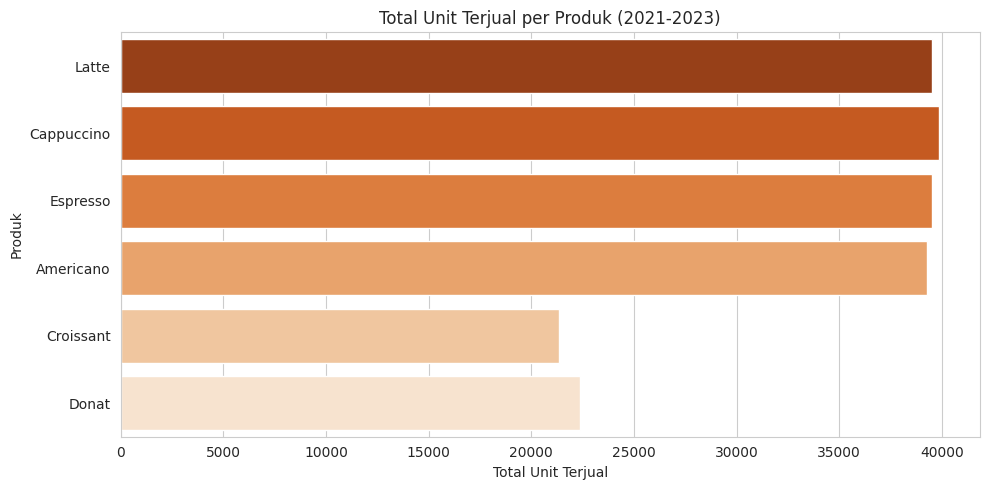

In [ ]:

# 1. Total unit & pendapatan per produk
total_per_produk = df.groupby('Produk').agg(
    Total_Unit=('Unit_Terjual', 'sum'),
    Total_Pendapatan=('Pendapatan', 'sum')
).sort_values('Total_Pendapatan', ascending=False)
print("Total unit & pendapatan per produk:")
print(total_per_produk)

# 2. Rata-rata unit terjual per hari, tiap produk, tiap tahun
rata_rata_harian = df.groupby(['Tahun', 'Produk'])['Unit_Terjual'].mean().reset_index()
rata_rata_harian.columns = ['Tahun', 'Produk', 'Rata_Rata_Unit_Per_Hari']
print("\nRata-rata unit terjual per hari, per produk, per tahun:")
print(rata_rata_harian.sort_values(['Tahun', 'Rata_Rata_Unit_Per_Hari'], ascending=[True, False]))

# 3. Produk terlaris per tahun
penjualan_tahunan = df.groupby(['Tahun', 'Produk'])['Unit_Terjual'].sum().reset_index()
produk_terlaris = penjualan_tahunan.loc[penjualan_tahunan.groupby('Tahun')['Unit_Terjual'].idxmax()]
print("\nProduk terlaris per tahun:")
print(produk_terlaris.reset_index(drop=True))

# 4. Grafik batang total unit jual per produk (2021-2023)
plt.figure()
sns.barplot(data=total_per_produk.reset_index(), x='Total_Unit', y='Produk', hue='Produk', palette='Oranges_r', legend=False)
plt.title('Total Unit Terjual per Produk (2021-2023)')
plt.xlabel('Total Unit Terjual')
plt.ylabel('Produk')
plt.tight_layout()
plt.show()


**Insight analisis per produk**

- Empat minuman terjual hampir sama banyak (39.265 sampai 39.859 unit, selisih sekitar 1,5%). Croissant (21.360) dan Donat (22.379) terjual sekitar separuhnya.
- Latte memiliki pendapatan tertinggi (Rp1.128.724.240) karena harganya paling tinggi (Rp28.000 pada 2021), bukan karena paling banyak terjual. Unit Latte (39.528) justru di bawah Cappuccino (39.859).
- Produk terlaris berganti tiap tahun (Americano 2021, Cappuccino 2022, Espresso 2023), tetapi selisihnya sangat tipis. Lebih tepat dibaca sebagai volume minuman yang setara, bukan pergeseran preferensi pelanggan.
- Donat memiliki pendapatan terendah (Rp342.290.700) karena harganya paling rendah (Rp15.000) dan volumenya hanya sekitar separuh produk minuman.



---


## TUGAS 5: Rangkuman & Insight

- Tulis ringkasan hasil:
- Sampaikan minimal 2 rekomendasi untuk bisnis.

In [ ]:

produk_top = total_per_produk.index[0]
produk_bottom = total_per_produk.index[-1]

print("=" * 60)
print("RINGKASAN HASIL ANALISIS")
print("=" * 60)
print(f"- Produk dengan pendapatan tertinggi: {produk_top} (Rp {total_per_produk.loc[produk_top, 'Total_Pendapatan']:,.0f})")
print(f"- Produk dengan pendapatan terendah: {produk_bottom} (Rp {total_per_produk.loc[produk_bottom, 'Total_Pendapatan']:,.0f})")
for tahun in sorted(produk_terlaris['Tahun'].unique()):
    p = produk_terlaris[produk_terlaris['Tahun'] == tahun]['Produk'].values[0]
    print(f"- Produk terlaris tahun {tahun}: {p}")

print("\nRekomendasi bisnis:")
print(f"1. Perkuat stok dan promosi untuk {produk_top} karena kontribusinya paling besar terhadap pendapatan.")
print(f"2. Buat paket bundling atau promo untuk {produk_bottom} agar penjualannya terdongkrak, mengingat kontribusinya masih rendah dibanding produk lain.")


RINGKASAN HASIL ANALISIS
- Produk dengan pendapatan tertinggi: Latte (Rp 1,128,724,240)
- Produk dengan pendapatan terendah: Donat (Rp 342,290,700)
- Produk terlaris tahun 2021: Americano
- Produk terlaris tahun 2022: Cappuccino
- Produk terlaris tahun 2023: Espresso

Rekomendasi bisnis:
1. Perkuat stok dan promosi untuk Latte karena kontribusinya paling besar terhadap pendapatan.
2. Buat paket bundling atau promo untuk Donat agar penjualannya terdongkrak, mengingat kontribusinya masih rendah dibanding produk lain.


## 🌟 Tugas Opsional / Challenge (Pilihan):



1. **Identifikasi Bulan Tertinggi dan Terendah**
   
   - Temukan bulan dan tahun dengan total penjualan unit tertinggi dan terendah (dalam seluruh periode).
   - Visualisasikan trennya (misal line chart penjualan bulanan).

2. **Analisis Pertumbuhan Penjualan**
   
   - Bandingkan total penjualan (unit terjual maupun pendapatan) antar tahun 2021, 2022, dan 2023.
   - Produk apa yang pertumbuhannya paling tinggi selama 3 tahun?
   - Tampilkan hasilnya dalam bentuk tabel ringkasan pertumbuhan dan/atau visualisasi sederhana.

3. **Simulasi Promo Diskon**
   
   - Simulasikan jika ada diskon 10% untuk produk minuman di bulan-bulan tertentu (misal: Juli & Agustus), dan asumsikan penjualan produk-produk ini naik 15% di bulan promo.
   - Hitung dan bandingkan pendapatan asli vs pendapatan setelah promo.
   - Jelaskan insight-nya, apakah strategi promo ini efektif? (Boleh angka “kasar”, tidak harus persis.)

4. **Deteksi Outlier**
   
   - Temukan hari-hari/tanggal tertentu dimana penjualan produk “melonjak tidak wajar” (misal, tiga kali lipat dari median hariannya).
   - Buat list tanggal tersebut dan sebutkan produk apa saja yang menjadi “outlier”.
   - Akan lebih baik jika langsung ditampilkan dalam bentuk boxplot

5. **Cek Konsistensi Harga**
   
   - Adakah harga produk yang tidak sesuai aturan/rumus kenaikan 2% per tahun? (Cek kolom Harga_Per_Unit)
   - Jika ada data yang tidak konsisten, tampilkan semua kasusnya dan buat analisa ringkas.

---

**Instruksi untuk peserta (opsional):**
Pilih satu atau lebih tugas opsional di atas, lakukan analisis menggunakan pandas, groupby, serta visualisasi yang dikuasai. Laporan insight dan hasil analisis ditulis ringkas namun jelas.

---

Still hungry of challenge ?
[Try this dataset](https://drive.google.com/file/d/1XQDy8Li_EKcC1QOez1dtjKLguY_MyVOO/view?usp=drive_link)

Challenge 1 : Identifikasi Bulan Tertinggi dan Terendah

Bulan dengan total unit terjual TERTINGGI sepanjang periode:
Tahun           2022
Bulan_Angka        3
Unit_Terjual    6024
Name: 14, dtype: int64

Bulan dengan total unit terjual TERENDAH sepanjang periode:
Tahun           2022
Bulan_Angka        2
Unit_Terjual    5011
Name: 13, dtype: int64


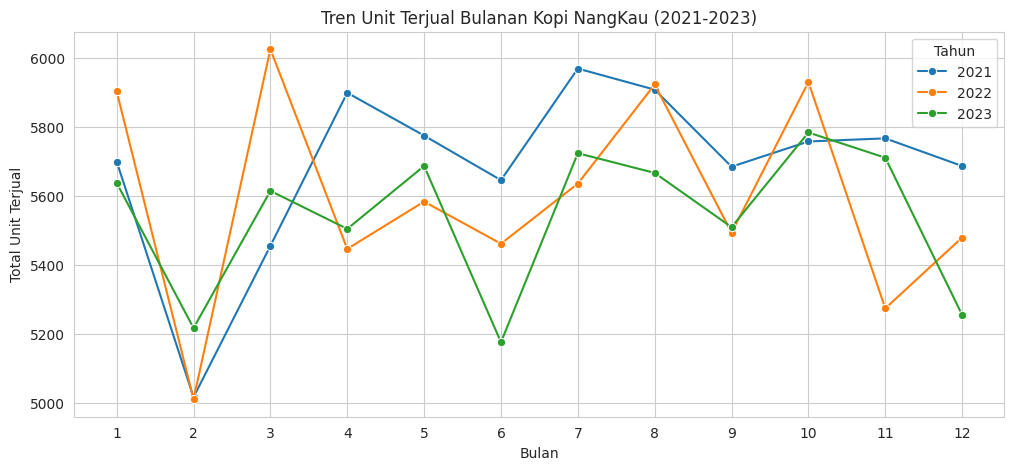

In [ ]:

bulan_agg = df.groupby(['Tahun', 'Bulan_Angka'])['Unit_Terjual'].sum().reset_index()
bulan_tertinggi = bulan_agg.loc[bulan_agg['Unit_Terjual'].idxmax()]
bulan_terendah = bulan_agg.loc[bulan_agg['Unit_Terjual'].idxmin()]

print("Bulan dengan total unit terjual TERTINGGI sepanjang periode:")
print(bulan_tertinggi)
print("\nBulan dengan total unit terjual TERENDAH sepanjang periode:")
print(bulan_terendah)

plt.figure(figsize=(12, 5))
sns.lineplot(data=bulan_agg, x='Bulan_Angka', y='Unit_Terjual', hue='Tahun', marker='o', palette='tab10')
plt.title('Tren Unit Terjual Bulanan Kopi NangKau (2021-2023)')
plt.xlabel('Bulan')
plt.ylabel('Total Unit Terjual')
plt.xticks(range(1, 13))
plt.legend(title='Tahun')
plt.show()

**Insight tren bulanan**

- Total unit tertinggi: Maret 2022 (6.024 unit). Terendah: Februari 2022 (5.011 unit).
- Februari juga menjadi titik terendah pada 2021, sedangkan pada 2023 titik terendahnya Juni. Sebagian besar penyebab Februari rendah adalah efek kalender, karena Februari hanya 28 hari. Jika dibagi jumlah hari kalender, Februari 2022 sekitar 179 unit per hari, dibanding sekitar 194 unit per hari pada Maret 2022.
- Di luar Februari, tidak terlihat pola musiman yang konsisten antar tahun (puncak dan lembah bulanan berbeda di tiap tahun).

Challenge 2 : Analisis Pertumbuhan Penjualan

Pertumbuhan total penjualan antar tahun:
   Tahun  Total_Unit  Total_Pendapatan  Pertumbuhan_Unit (%)  \
0   2021       68256        1526431000                   NaN   
1   2022       67159        1532470440             -1.607185   
2   2023       66480        1547752960             -1.011034   

   Pertumbuhan_Pendapatan (%)  
0                         NaN  
1                    0.395658  
2                    0.997247  

Pertumbuhan pendapatan per produk dari 2021 ke 2023:
Tahun            2021       2022       2023  Pertumbuhan_2021_ke_2023 (%)
Produk                                                                   
Espresso    288970000  294435240  303114240                      4.894709
Croissant   128034000  133715880  130366080                      1.821454
Cappuccino  334850000  340884000  340522000                      1.693893
Latte       375508000  372850800  380365440                      1.293565
Donat       115485000  112317300  114488400                     -0.862969
Am

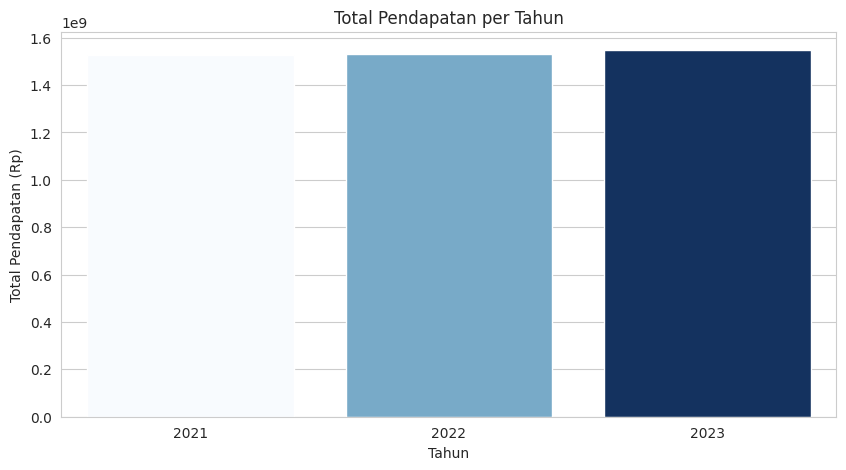

In [ ]:

pertumbuhan_tahunan = df.groupby('Tahun').agg(
    Total_Unit=('Unit_Terjual', 'sum'),
    Total_Pendapatan=('Pendapatan', 'sum')
).reset_index()
pertumbuhan_tahunan['Pertumbuhan_Unit (%)'] = pertumbuhan_tahunan['Total_Unit'].pct_change() * 100
pertumbuhan_tahunan['Pertumbuhan_Pendapatan (%)'] = pertumbuhan_tahunan['Total_Pendapatan'].pct_change() * 100
print("Pertumbuhan total penjualan antar tahun:")
print(pertumbuhan_tahunan)

# Produk dengan pertumbuhan pendapatan tertinggi selama 3 tahun (2021 -> 2023)
pendapatan_produk_tahun = df.groupby(['Produk', 'Tahun'])['Pendapatan'].sum().unstack()
pendapatan_produk_tahun['Pertumbuhan_2021_ke_2023 (%)'] = (
    (pendapatan_produk_tahun[2023] - pendapatan_produk_tahun[2021]) / pendapatan_produk_tahun[2021] * 100
)
print("\nPertumbuhan pendapatan per produk dari 2021 ke 2023:")
print(pendapatan_produk_tahun.sort_values('Pertumbuhan_2021_ke_2023 (%)', ascending=False))

plt.figure()
sns.barplot(data=pertumbuhan_tahunan, x='Tahun', y='Total_Pendapatan', hue='Tahun', palette='Blues', legend=False)
plt.title('Total Pendapatan per Tahun')
plt.ylabel('Total Pendapatan (Rp)')
plt.show()


**Insight pertumbuhan**

- Total pendapatan naik tipis: Rp1,526 M (2021), Rp1,532 M (2022), Rp1,548 M (2023), atau sekitar +1,4% dalam dua tahun.
- Harga naik 2% per tahun (4% pada 2023 dibanding 2021), sedangkan pendapatan hanya naik 1,4%. Artinya kenaikan pendapatan berasal dari harga, bukan dari volume. Unit terjual turun dari 68.256 (2021) menjadi 66.480 (2023), sekitar -2,6%.
- Pertumbuhan pendapatan 2021 ke 2023 tertinggi pada Espresso (+4,89%) dan terendah pada Americano (-1,65%). Karena harga sudah naik 4%, volume Espresso kurang lebih stabil, sedangkan volume Americano dan Donat menurun.
- **Catatan kehati-hatian:** selisih unit antar tahun kecil (1% sampai 2,6%) dan baris yang dihapus tidak merata antar tahun. Sel di bawah memeriksa hal ini dengan kelengkapan data dan rata-rata unit per hari.

In [ ]:
# Cek keadilan perbandingan antar tahun
# 1) Berapa persen data yang tersisa per tahun? (lengkap = 6 produk x 365 hari = 2.190 baris)
kelengkapan = df.groupby('Tahun').size().to_frame('Jumlah_Baris')
kelengkapan['Baris_Lengkap'] = 6 * 365
kelengkapan['Data_Tersisa (%)'] = (kelengkapan['Jumlah_Baris'] / kelengkapan['Baris_Lengkap'] * 100).round(1)
print(kelengkapan)

# 2) Rata-rata unit per hari per produk (tidak terpengaruh baris yang hilang)
rata_per_hari = df.pivot_table(index='Produk', columns='Tahun', values='Unit_Terjual', aggfunc='mean').round(2)
rata_per_hari['Perubahan_2021_ke_2023 (%)'] = ((rata_per_hari[2023] - rata_per_hari[2021]) / rata_per_hari[2021] * 100).round(2)
print()
print(rata_per_hari)

Challenge 3 : Simulasi Promo Diskon

In [ ]:

# Diskon 10% untuk produk MINUMAN di bulan Juli & Agustus, asumsi unit naik 15%

produk_minuman = ['Espresso', 'Latte', 'Cappuccino', 'Americano']
mask_promo = df['Produk'].isin(produk_minuman) & df['Bulan_Angka'].isin([7, 8])

data_promo = df[mask_promo].copy()
pendapatan_asli = data_promo['Pendapatan'].sum()

# Simulasi: harga turun 10%, unit naik 15%
data_promo['Harga_Setelah_Promo'] = data_promo['Harga_Per_Unit'] * 0.90
data_promo['Unit_Setelah_Promo'] = data_promo['Unit_Terjual'] * 1.15
data_promo['Pendapatan_Setelah_Promo'] = data_promo['Harga_Setelah_Promo'] * data_promo['Unit_Setelah_Promo']

pendapatan_setelah_promo = data_promo['Pendapatan_Setelah_Promo'].sum()
selisih = pendapatan_setelah_promo - pendapatan_asli
dampak_persen = (selisih / pendapatan_asli) * 100

print(f"Pendapatan asli (Juli-Agustus, produk minuman): Rp {pendapatan_asli:,.0f}")
print(f"Pendapatan simulasi setelah promo: Rp {pendapatan_setelah_promo:,.0f}")
print(f"Selisih: Rp {selisih:,.0f} ({dampak_persen:.2f}%)")

if dampak_persen > 0:
    print(f"Insight kasar: promo diskon 10% di bulan Juli-Agustus BERPOTENSI EFEKTIF, karena kenaikan unit 15% lebih besar dari penurunan harga 10%, sehingga pendapatan naik sekitar {dampak_persen:.1f}%.")
else:
    print(f"Insight kasar: promo diskon 10% di bulan Juli-Agustus BERPOTENSI KURANG EFEKTIF, karena kenaikan unit 15% tidak cukup menutup penurunan harga 10%, pendapatan turun sekitar {abs(dampak_persen):.1f}%.")


Pendapatan asli (Juli-Agustus, produk minuman): Rp 672,048,100
Pendapatan simulasi setelah promo: Rp 695,569,784
Selisih: Rp 23,521,684 (3.50%)
Insight kasar: promo diskon 10% di bulan Juli-Agustus BERPOTENSI EFEKTIF, karena kenaikan unit 15% lebih besar dari penurunan harga 10%, sehingga pendapatan naik sekitar 3.5%.


**Insight simulasi promo**

- Pendapatan asli (minuman, Juli sampai Agustus): Rp672.048.100. Setelah simulasi: Rp695.569.784 (naik Rp23.521.684 atau 3,5%).
- Angka +3,5% pasti muncul dari asumsi, bukan dari data: 0,90 x 1,15 = 1,035. Data hanya menentukan nilai rupiahnya.
- Promo ini hanya terlihat menguntungkan dari sisi **pendapatan**. Kenaikan unit minimum agar pendapatan impas dengan diskon 10% adalah 1/0,9 - 1, sekitar 11,1%. Untuk **laba**, kenaikan unit yang dibutuhkan lebih besar dan bergantung pada margin, yang tidak tersedia di dataset ini. Contoh: dengan margin kotor 60%, kenaikan unit minimal sekitar 20% agar laba tidak turun, sehingga asumsi 15% belum cukup.

Challenge 4 : Deteksi Outlier

Jumlah baris outlier (unit >= 3x median produk): 0

Daftar tanggal & produk yang menjadi outlier (top 20):
Empty DataFrame
Columns: [Tanggal_Penjualan, Produk, Unit_Terjual, Median_Produk]
Index: []

Produk mana saja yang punya outlier:
Series([], Name: count, dtype: int64)


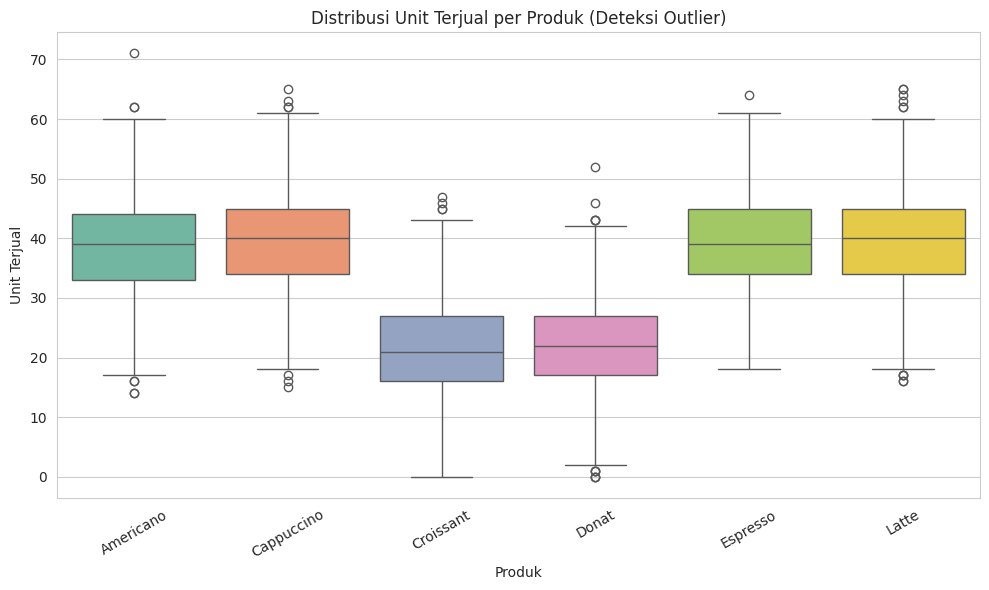

In [ ]:

# Penjualan "melonjak tidak wajar" = 3x lipat dari median harian produk tsb

median_per_produk = df.groupby('Produk')['Unit_Terjual'].median()
df['Median_Produk'] = df['Produk'].map(median_per_produk)
df['Outlier'] = df['Unit_Terjual'] >= (3 * df['Median_Produk'])

outlier_list = df[df['Outlier']][['Tanggal_Penjualan', 'Produk', 'Unit_Terjual', 'Median_Produk']] \
    .sort_values('Unit_Terjual', ascending=False)

print(f"Jumlah baris outlier (unit >= 3x median produk): {outlier_list.shape[0]}")
print("\nDaftar tanggal & produk yang menjadi outlier (top 20):")
print(outlier_list.head(20))

print("\nProduk mana saja yang punya outlier:")
print(df[df['Outlier']]['Produk'].value_counts())

# Boxplot per produk
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Produk', y='Unit_Terjual', hue='Produk', palette='Set2', legend=False)
plt.title('Distribusi Unit Terjual per Produk (Deteksi Outlier)')
plt.xlabel('Produk')
plt.ylabel('Unit Terjual')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Insight outlier**

- Tidak ada baris dengan penjualan >= 3x median produk, jadi tidak ada lonjakan yang tidak wajar menurut definisi tersebut.
- Boxplot menunjukkan beberapa titik di luar whisker (misalnya Americano hingga sekitar 71 unit dan Donat sekitar 52 unit), tetapi masih jauh di bawah 3x median (median Americano sekitar 39 unit, sehingga batasnya sekitar 117). Titik-titik itu termasuk variasi wajar.
- Croissant dan Donat memiliki hari dengan penjualan 0 unit. Perlu dicek apakah penyebabnya stok habis, toko tutup, atau kesalahan pencatatan.

Challenge 5 : Cek Konsistensi harga

In [ ]:

# Bandingkan Harga_Per_Unit aktual vs harga resmi (rumus kenaikan 2%/tahun)

df['Harga_Resmi'] = df.apply(lambda row: harga_standar(row['Produk'], row['Tahun']), axis=1)
df['Harga_Konsisten'] = df['Harga_Per_Unit'] == df['Harga_Resmi']

tidak_konsisten = df[~df['Harga_Konsisten']][
    ['Tanggal_Penjualan', 'Produk', 'Tahun', 'Harga_Per_Unit', 'Harga_Resmi']
]

print(f"Jumlah baris dengan harga TIDAK sesuai aturan kenaikan 2%/tahun: {tidak_konsisten.shape[0]}")
print("\nDaftar kasus harga tidak konsisten:")
print(tidak_konsisten)

if tidak_konsisten.shape[0] > 0:
    print("\nRingkasan per produk (jumlah baris tidak konsisten):")
    print(tidak_konsisten['Produk'].value_counts())
    print("\nAnalisis ringkas: ada indikasi kesalahan input harga atau harga promo/diskon yang tidak tercatat")
    print("terpisah dari harga normal. Sebaiknya dicek manual ke sumber data transaksi asli.")
else:
    print("\nSemua harga pada dataset sudah konsisten dengan aturan kenaikan 2% per tahun.")


Jumlah baris dengan harga TIDAK sesuai aturan kenaikan 2%/tahun: 0

Daftar kasus harga tidak konsisten:
Empty DataFrame
Columns: [Tanggal_Penjualan, Produk, Tahun, Harga_Per_Unit, Harga_Resmi]
Index: []

Semua harga pada dataset sudah konsisten dengan aturan kenaikan 2% per tahun.


**Insight konsistensi harga**

- Tidak ada baris yang harganya menyimpang dari aturan kenaikan 2% per tahun.
- **Catatan:** pengecekan di atas dilakukan setelah imputasi. Sebanyak 463 harga yang kosong sudah diisi dengan rumus yang sama, sehingga baris itu pasti lolos. Sel di bawah mengulang pengecekan hanya pada harga asli (sebelum imputasi).

In [ ]:
# Cek konsistensi hanya pada harga ASLI (sebelum imputasi)
mentah = pd.read_csv('/content/penjualan_kopi_2021_2023.csv', sep=';')
mentah['Harga_Per_Unit'] = pd.to_numeric(mentah['Harga_Per_Unit'], errors='coerce')
asli = mentah.dropna(subset=['Produk', 'Harga_Per_Unit']).copy()
asli['Harga_Resmi'] = asli.apply(lambda r: harga_standar(r['Produk'], r['Tahun']), axis=1)
menyimpang = asli[asli['Harga_Per_Unit'] != asli['Harga_Resmi']]
print(f"Baris dengan harga asli: {len(asli)}")
print(f"Baris dengan harga menyimpang dari aturan: {len(menyimpang)}")

---

## Kesimpulan dan Rekomendasi

**Kesimpulan**

- Penjualan stabil selama 2021 sampai 2023. Pendapatan naik tipis (sekitar 1,4%) dan kenaikan itu berasal dari harga, sementara volume cenderung turun sedikit.
- Empat minuman memiliki volume setara. Latte unggul di pendapatan karena harga, Donat dan Croissant adalah produk dengan kontribusi pendapatan terendah.
- Tidak ada lonjakan penjualan ekstrem dan tidak ada harga asli yang menyimpang dari aturan kenaikan 2% per tahun.
- Kualitas data perlu diperbaiki: 500 nilai kosong pada tiga kolom, duplikat, dan sekitar 8% hari-produk hilang setelah pembersihan.

**Rekomendasi**

1. Buat paket bundling minuman + makanan (misalnya Latte + Croissant) untuk mendorong penjualan Donat dan Croissant yang volumenya sekitar separuh minuman.
2. Jika promo diskon Juli sampai Agustus dijalankan, evaluasi dengan laba (butuh data margin), bukan hanya pendapatan, dan tentukan target kenaikan unit sebelum promo berjalan.
3. Perbaiki pencatatan data penjualan agar kolom produk, unit, dan harga tidak kosong, serta cek hari dengan penjualan 0 unit.